# Telco Customer Churn Prediction – Machine Learning Project

**Goal:** Predict whether a telecom customer will churn (leave the company) using the IBM Telco Customer Churn dataset.

**Workflow:**
1. Load & clean the data
2. Exploratory data analysis (EDA)
3. Train/test split & preprocessing pipeline
4. Compare baseline models
5. Tune the Random Forest with RandomizedSearchCV
6. Evaluate (confusion matrix, ROC-AUC, feature importance)
7. Save the final model with joblib

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, joblib

In [80]:
# PURPOSE: Import all libraries (data handling, plotting, scikit-learn tools, metrics) and set global display options.
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay, make_scorer
)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [6]:
# PURPOSE: Import helper modules for unzipping the dataset and working with file paths.
import pandas as pd
import zipfile
import os

In [7]:
# PURPOSE: Extract the downloaded Kaggle archive (zip) into a local 'dataset' folder.
# NOTE: Change zip_path to wherever the archive is on your machine.
zip_path = r"C:\Users\FITS\Downloads\archive.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [8]:
# PURPOSE: List the extracted folder contents to confirm the unzip worked.
os.listdir("dataset")

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [9]:
# PURPOSE: Search the dataset folder recursively and print the path of every CSV file.
for root, dirs, files in os.walk("dataset"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [21]:
# PURPOSE: Load the Telco Customer Churn CSV into a pandas DataFrame called `data`.
data = pd.read_csv(r"dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [22]:
# PURPOSE: Preview the first 5 rows to understand the columns and values.
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
# PURPOSE: Check column data types, non-null counts and memory usage (spots wrongly typed columns like TotalCharges).
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [24]:
# PURPOSE: Count missing values per column (before cleaning).
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [25]:
# PURPOSE: Convert TotalCharges from text to numeric; invalid/blank entries become NaN.
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'], errors='coerce'
)

In [26]:
# PURPOSE: Safer re-conversion of TotalCharges: strip whitespace first so blank strings become NaN properly.
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'].astype(str).str.strip(),
    errors='coerce'
)

In [48]:
# PURPOSE: Fill the missing TotalCharges values with the column median.
data['TotalCharges'] = data['TotalCharges'].fillna(
    data['TotalCharges'].median()
)

In [49]:
# PURPOSE: Re-check missing values to confirm the data is now clean.
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

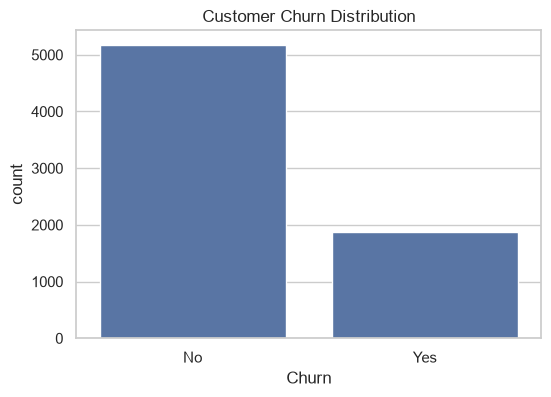

In [81]:
# PURPOSE (EDA): Show how many customers churned vs. stayed (checks class imbalance).
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

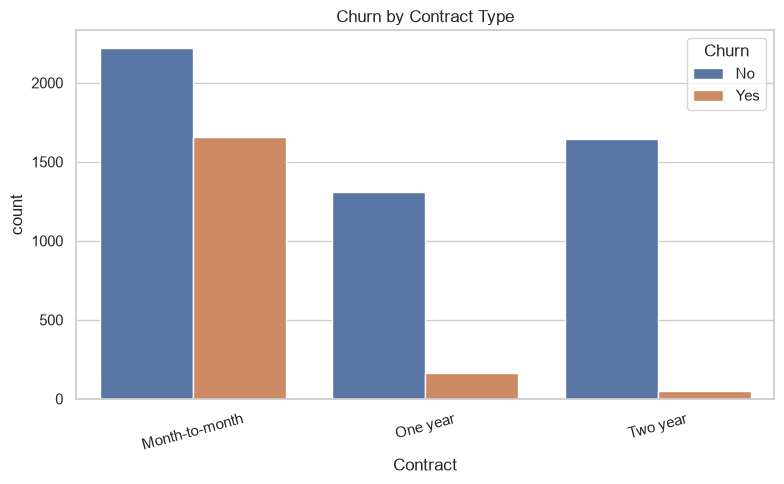

In [82]:
# PURPOSE (EDA): Compare churn across contract types (Month-to-month, One year, Two year).
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

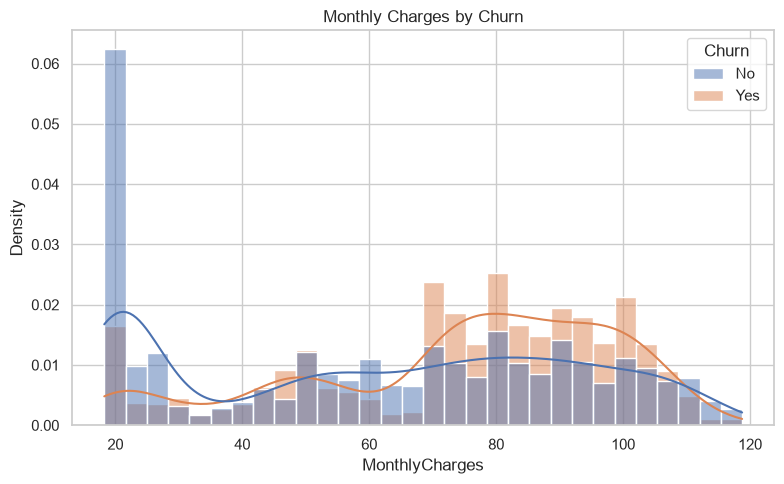

In [83]:
# PURPOSE (EDA): Compare the MonthlyCharges distribution of churned vs. retained customers.
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="MonthlyCharges", hue="Churn", bins=30,
             kde=True, stat="density", common_norm=False)
plt.title("Monthly Charges by Churn")
plt.tight_layout()
plt.show()

,Churn rate
TenureGroup,
0-12,0.474382
13-24,0.287109
25-48,0.203890
49-60,0.144231
61-72,0.066098


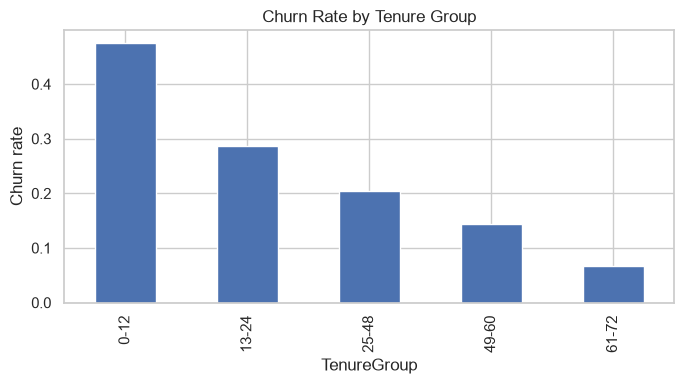

In [84]:
# PURPOSE (EDA): Group customers by tenure (months) and plot the churn rate for each group.
eda = data.copy()
eda["TenureGroup"] = pd.cut(
    eda["tenure"], bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
)
rate = eda.groupby("TenureGroup", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean())
display(rate.rename("Churn rate").to_frame())
rate.plot(kind="bar", figsize=(7, 4), title="Churn Rate by Tenure Group", ylabel="Churn rate")
plt.tight_layout()
plt.show()

In [85]:
# PURPOSE: Build the feature matrix X by dropping the target (Churn) and the ID column (customerID).
X = data.drop(['Churn', 'customerID'],axis=1,errors="ignore")
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60


In [86]:
# PURPOSE: Define the target variable y (Churn: Yes/No).
y = data['Churn']
y

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: str

In [87]:
# PURPOSE: Split into 80% train / 20% test; stratify keeps the churn ratio the same in both sets.
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42, stratify=y)

In [88]:
# PURPOSE: Verify the split shapes and that churn proportions match in train and test sets.
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train target proportions:")
display(y_train.value_counts(normalize=True))
print("Test target proportions:")
display(y_test.value_counts(normalize=True))

Train: (5634, 19) Test: (1409, 19)
Train target proportions:


Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64

Test target proportions:


Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64

In [89]:
# PURPOSE: Build the preprocessing pipeline:
#   numeric columns -> median imputation + scaling
#   categorical columns -> most-frequent imputation + one-hot encoding
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [94]:
# PURPOSE: Train and compare 4 models (Dummy baseline, Logistic Regression, Decision Tree, Random Forest)
# using the same preprocessing, and rank them by F1 score for the churn class.
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced", n_jobs=-1
    )
}

fitted_models = {}
rows = []

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Yes)": precision_score(y_test, pred, pos_label="Yes", zero_division=0),
        "Recall (Yes)": recall_score(y_test, pred, pos_label="Yes", zero_division=0),
        "F1 (Yes)": f1_score(y_test, pred, pos_label="Yes", zero_division=0)
    })

results_df = pd.DataFrame(rows).sort_values("F1 (Yes)", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
1,Logistic Regression,0.738,0.504,0.783,0.614
3,Random Forest,0.764,0.548,0.620,0.582
2,Decision Tree,0.732,0.495,0.487,0.491
0,Dummy baseline,0.735,0.000,0.000,0.000


Accuracy: 0.7637
              precision    recall  f1-score   support

          No       0.86      0.82      0.84      1035
         Yes       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



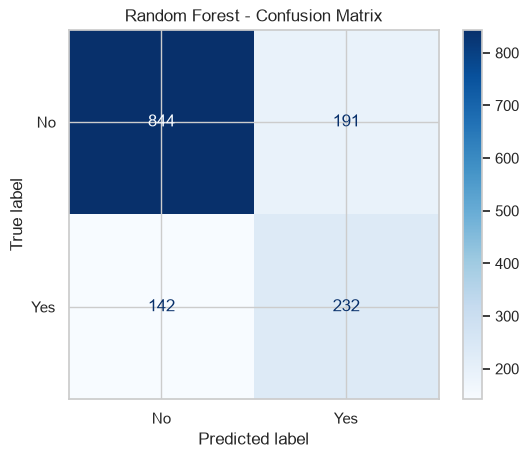

In [95]:
# PURPOSE: Evaluate the baseline Random Forest: accuracy, classification report and confusion matrix.
baseline_rf = fitted_models["Random Forest"]
pred = baseline_rf.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=["No", "Yes"])
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [96]:
# PURPOSE: Hyperparameter tuning of Random Forest with RandomizedSearchCV (3-fold stratified CV, optimising churn F1).
churn_f1 = make_scorer(f1_score, pos_label="Yes")

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

param_distributions = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions,
    n_iter=8,
    scoring=churn_f1,
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=2,
    refit=True
)

search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Best CV F1 (Yes):", round(search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV F1 (Yes): 0.6342


In [97]:
# PURPOSE: Evaluate the best tuned model on the unseen test set (accuracy, precision, recall, F1, report).
best_model = search.best_estimator_
final_pred = best_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Precision (Yes):", round(precision_score(y_test, final_pred, pos_label="Yes", zero_division=0), 4))
print("Recall (Yes):", round(recall_score(y_test, final_pred, pos_label="Yes", zero_division=0), 4))
print("F1 (Yes):", round(f1_score(y_test, final_pred, pos_label="Yes", zero_division=0), 4))
print("\\n", classification_report(y_test, final_pred, zero_division=0))

Accuracy: 0.7523
Precision (Yes): 0.5229
Recall (Yes): 0.762
F1 (Yes): 0.6202
\n               precision    recall  f1-score   support

          No       0.90      0.75      0.82      1035
         Yes       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



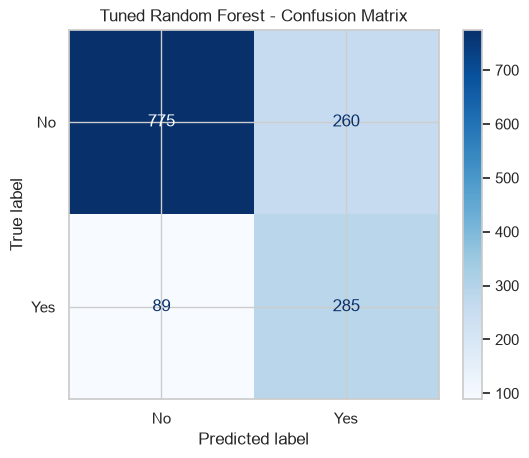

In [98]:
# PURPOSE: Plot the confusion matrix of the tuned Random Forest.
cm = confusion_matrix(y_test, final_pred, labels=["No", "Yes"])
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(cmap="Blues")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

ROC-AUC: 0.8387


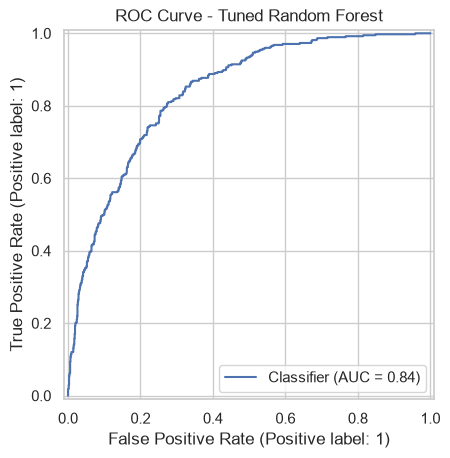

In [99]:
# PURPOSE: Compute ROC-AUC and plot the ROC curve using predicted churn probabilities.
yes_index = list(best_model.classes_).index("Yes")
prob_yes = best_model.predict_proba(X_test)[:, yes_index]
print("ROC-AUC:", round(roc_auc_score((y_test == "Yes").astype(int), prob_yes), 4))
RocCurveDisplay.from_predictions((y_test == "Yes").astype(int), prob_yes)
plt.title("ROC Curve - Tuned Random Forest")
plt.show()

,Feature,Importance
14,Contract,0.093655
7,InternetService,0.027442
4,tenure,0.016062
18,TotalCharges,0.005250
12,StreamingTV,0.003703
13,StreamingMovies,0.002215
5,PhoneService,0.001045
15,PaperlessBilling,-0.000746
9,OnlineBackup,-0.001067
10,DeviceProtection,-0.001195


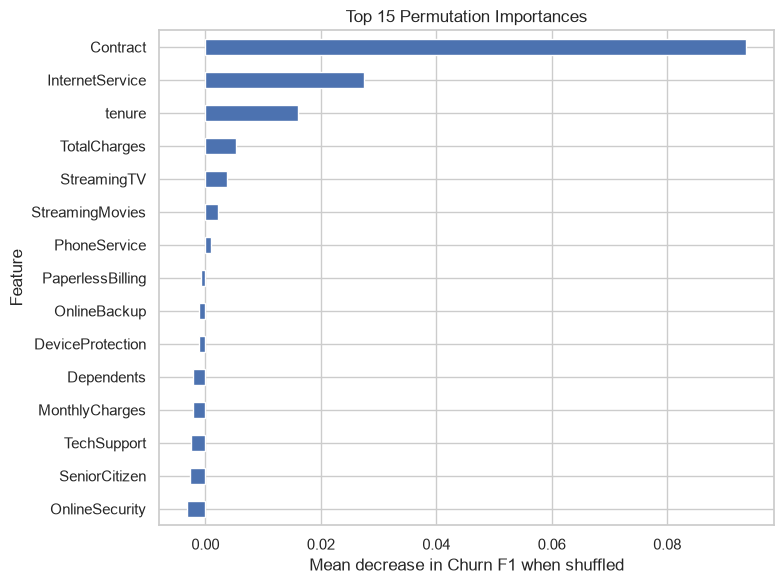

In [100]:
# PURPOSE: Find the most influential features with permutation importance (drop in F1 when a feature is shuffled).
sample_n = min(1000, len(X_test))
X_imp = X_test.sample(sample_n, random_state=42)
y_imp = y_test.loc[X_imp.index]

perm = permutation_importance(
    best_model, X_imp, y_imp,
    scoring=churn_f1, n_repeats=5,
    random_state=42, n_jobs=1
)

importance = pd.DataFrame({
    "Feature": X_imp.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

display(importance.head(15))
importance.head(15).sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh", legend=False, figsize=(8, 6)
)
plt.title("Top 15 Permutation Importances")
plt.xlabel("Mean decrease in Churn F1 when shuffled")
plt.tight_layout()
plt.show()

In [101]:
# PURPOSE: Save the trained pipeline to a .joblib file so it can be reused (e.g. in a Streamlit app).
MODEL_PATH = "telco_churn_pipeline.joblib"
joblib.dump(best_model, MODEL_PATH)
print("Saved:", MODEL_PATH)

Saved: telco_churn_pipeline.joblib


In [102]:
# PURPOSE: Sanity-check the model on one test customer: actual vs. predicted churn and churn probability.
example = X_test.iloc[[0]]
actual = y_test.iloc[0]
predicted = best_model.predict(example)[0]
probability = best_model.predict_proba(example)[0][yes_index]

print("Actual churn:", actual)
print("Predicted churn:", predicted)
print("Probability of churn:", round(probability, 3))
display(example)

Actual churn: No
Predicted churn: No
Probability of churn: 0.017


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2
